# Practical 10: Ensemble Learning (Random Forest and Boosting) vs a Baseline Model

**Subject:** Machine Learning  |  **Type:** Supervised learning, classification

## Aim
Analyse the performance of **ensemble learning techniques such as Random Forest or Boosting** on a suitable open-access dataset in comparison with a **baseline machine learning model**.

## Dataset
**Breast Cancer Wisconsin** (569 samples, 30 features, malignant vs benign).

## Models compared
| Model | Type | Role |
|---|---|---|
| **Dummy (majority class)** | no learning | Weakest baseline: "always predict the most common class" |
| **Decision Tree** | single model | **Main baseline** |
| **Random Forest** | **Bagging** ensemble of trees | Ensemble 1 |
| **AdaBoost** | **Boosting** | Ensemble 2 |
| **Gradient Boosting** | **Boosting** | Ensemble 3 |

## Steps
1. Load, split
2. Train all models, compare accuracy, precision, recall, F1, AUC
3. Cross-validation (stability)
4. Confusion matrices, ROC curves
5. Feature importance
6. Effect of number of trees
7. Out-of-bag (OOB) estimate

## Step 0: Import libraries

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")

## Step 1: Load and split

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = 1 - data.target                          # 1 = malignant (positive), 0 = benign
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| malignant share: %.2f" % y.mean())

Train: (426, 30) | Test: (143, 30) | malignant share: 0.37


**No scaling is needed** for tree-based models: trees split on thresholds, so they are unaffected by feature scale.

## Step 2: Train all models and compare

In [3]:
models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Decision Tree (baseline)": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
}
rows, preds, probs = [], {}, {}
for name, m in models.items():
    t0 = time.perf_counter()
    m.fit(X_train, y_train)
    fit_t = time.perf_counter() - t0
    p = m.predict(X_test)
    pr = m.predict_proba(X_test)[:, 1]
    preds[name], probs[name] = p, pr
    rows.append({"Model": name,
                 "Train acc": accuracy_score(y_train, m.predict(X_train)),
                 "Test acc": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p, zero_division=0),
                 "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p),
                 "AUC": roc_auc_score(y_test, pr),
                 "Fit time (s)": fit_t})
res = pd.DataFrame(rows).set_index("Model").round(4)
res

,Train acc,Test acc,Precision,Recall,F1,AUC,Fit time (s)
Model,,,,,,,
Dummy (majority),0.6268,0.6294,0.0000,0.0000,0.0000,0.5000,0.0139
Decision Tree (baseline),1.0000,0.9580,0.9796,0.9057,0.9412,0.9473,0.0111
Random Forest,1.0000,0.9580,1.0000,0.8868,0.9400,0.9955,0.3713
AdaBoost,1.0000,0.9720,1.0000,0.9245,0.9608,0.9945,0.5463
Gradient Boosting,1.0000,0.9650,1.0000,0.9057,0.9505,0.9960,0.6493


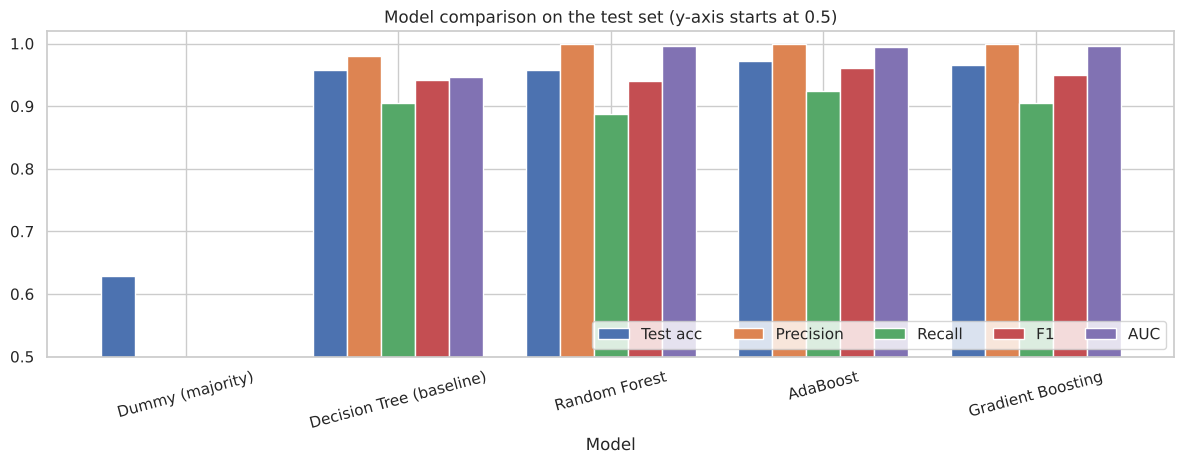

In [4]:
ax = res[["Test acc", "Precision", "Recall", "F1", "AUC"]].plot(kind="bar", figsize=(12, 4.8), rot=15, width=0.8)
ax.set_ylim(0.5, 1.02); ax.set_title("Model comparison on the test set (y-axis starts at 0.5)")
ax.legend(loc="lower right", ncol=5); plt.tight_layout(); plt.show()

**How to read this chart:** each group of bars is a model, each colour a metric.
- The **Dummy** model shows what "no learning" achieves (accuracy 0.63 = the majority-class share, recall 0): any real model must beat it.
- The **single Decision Tree** is the main baseline: test accuracy 0.958. **AdaBoost (0.972) and Gradient Boosting (0.965) are higher, but Random Forest ties the tree at 0.958.** With only 143 test samples one patient is 0.7%, so these accuracy differences are within noise: do **not** claim the ensembles clearly win on accuracy from this one split. Also note the Random Forest has the *lowest recall* of the real models (0.887 vs the tree's 0.906) although its precision is 1.0.
- The **clear difference is AUC** (how well the model ranks malignant above benign): about **0.995 for all three ensembles vs 0.947 for the single tree**. Averaging many trees gives smoother, better probabilities than one tree's few blocky ones. Cross-validation (Step 3) is the better evidence for the overall ranking.
- The **Train acc** column shows the tree and all ensembles reaching 1.0 on training data: they fit the training set perfectly, so judge them on the **test** data.

## Step 3: Cross-validation (is the improvement stable?)

                            mean     std
Decision Tree (baseline)  0.9262  0.0245
Random Forest             0.9526  0.0351
AdaBoost                  0.9772  0.0144
Gradient Boosting         0.9596  0.0275


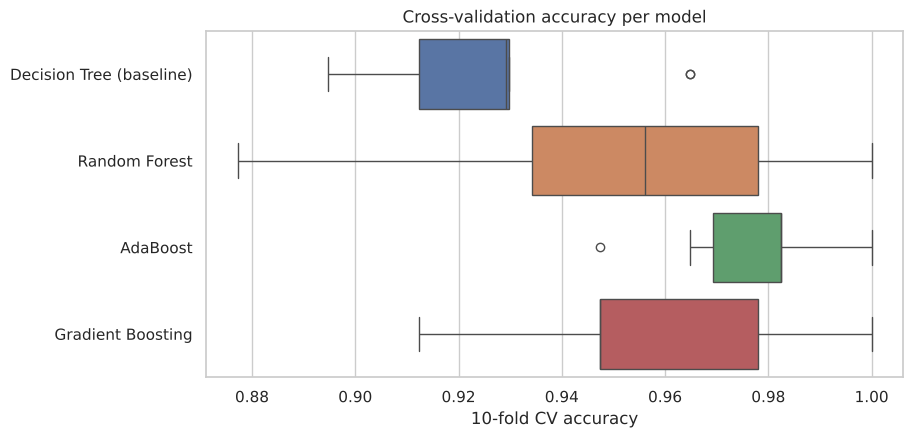

In [5]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_res = {}
for name, m in models.items():
    if name.startswith("Dummy"): continue
    cv_res[name] = cross_val_score(m, X, y, cv=skf, scoring="accuracy")

cv_df = pd.DataFrame(cv_res)
print(cv_df.agg(["mean", "std"]).T.round(4))

plt.figure(figsize=(9, 4.5))
sns.boxplot(data=cv_df, orient="h"); plt.xlabel("10-fold CV accuracy"); plt.title("Cross-validation accuracy per model")
plt.show()

**How to read the boxplot:** each box shows the spread of accuracy over 10 folds: the line in the box is the median, the box covers the middle 50%, and dots are unusual folds. A **higher** box means better accuracy, and a **narrower** box means more **stable** results.

**What my run shows (mean ± std over 10 folds):** Decision Tree 0.926 ± 0.025, Random Forest 0.953 ± 0.035, Gradient Boosting 0.960 ± 0.028, **AdaBoost 0.977 ± 0.014**. So **every ensemble has a higher mean accuracy than the single tree (by 3 to 5 points)**, which is the more reliable evidence than the single test split. About stability: only AdaBoost is clearly more stable; the Random Forest actually has a slightly *larger* spread than the tree here. In theory ensembles reduce variance, but with 569 samples the std estimates themselves are noisy, so describe what you see rather than a textbook claim.

## Step 4: Confusion matrices and ROC curves

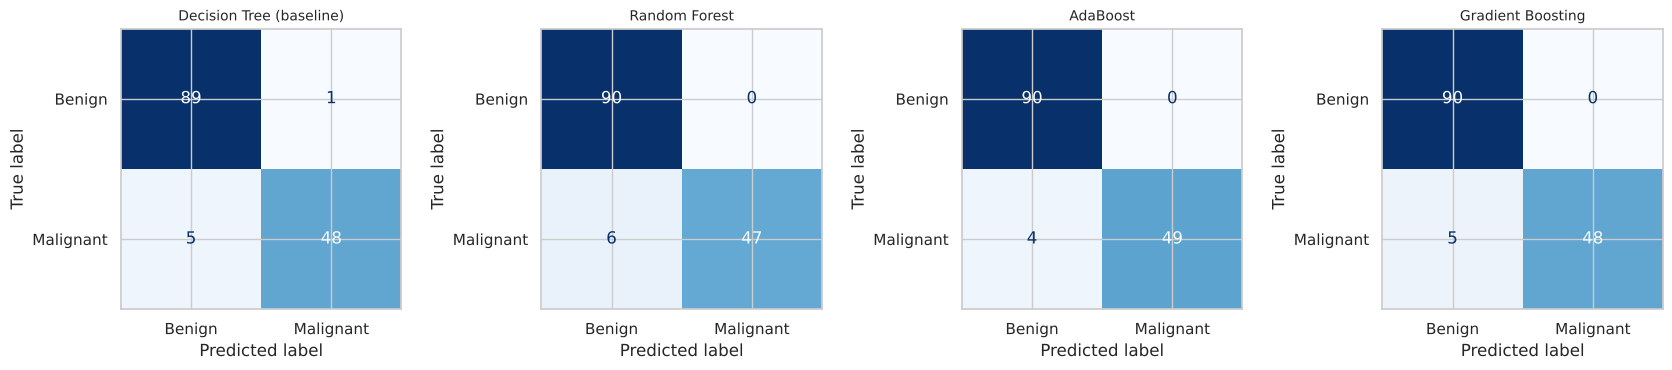

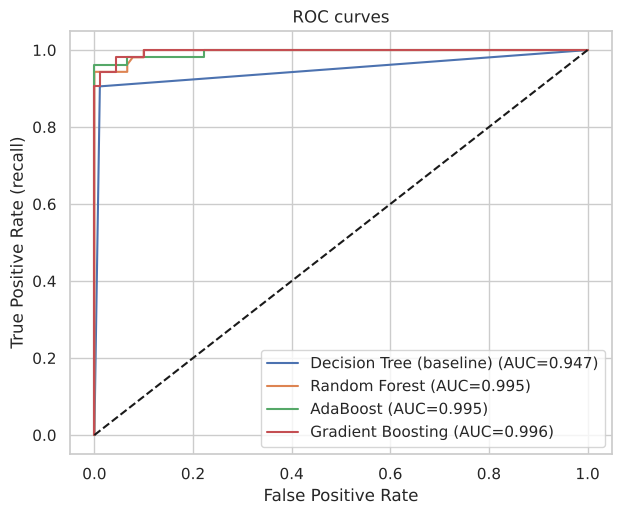

In [6]:
show = ["Decision Tree (baseline)", "Random Forest", "AdaBoost", "Gradient Boosting"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, n in zip(ax, show):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[n]), display_labels=["Benign", "Malignant"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(n, fontsize=10)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5.5))
for n in show:
    fpr, tpr, _ = roc_curve(y_test, probs[n])
    plt.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, probs[n]):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (recall)")
plt.title("ROC curves"); plt.legend(loc="lower right"); plt.show()

**How to read these:**
- **Confusion matrices:** the diagonal holds correct predictions. Compare the off-diagonal cells (mistakes) between the tree and the ensembles: the dangerous cell is the bottom-left, **FN** (a malignant case predicted benign).
- **ROC curves:** a curve closer to the top-left corner is better. The ensembles' curves hug the corner more tightly than the single tree, whose curve has a few big steps because a tree outputs only a handful of distinct probabilities.

## Step 5: Feature importance (Random Forest)

worst perimeter         0.1504
worst area              0.1213
worst concave points    0.1031
mean concave points     0.1015
worst radius            0.0825
mean perimeter          0.0618
mean radius             0.0610
mean area               0.0478
mean concavity          0.0398
area error              0.0303
dtype: float64


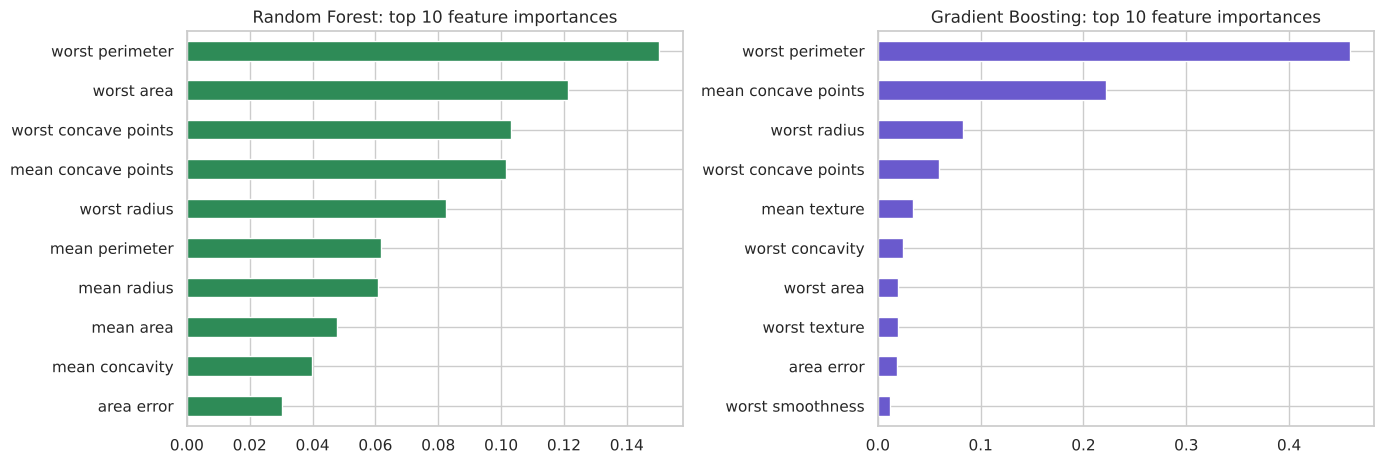

In [7]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(10).round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
imp.head(10)[::-1].plot(kind="barh", ax=ax[0], color="seagreen"); ax[0].set_title("Random Forest: top 10 feature importances")
gb_imp = pd.Series(models["Gradient Boosting"].feature_importances_, index=X.columns).sort_values(ascending=False)
gb_imp.head(10)[::-1].plot(kind="barh", ax=ax[1], color="slateblue"); ax[1].set_title("Gradient Boosting: top 10 feature importances")
plt.tight_layout(); plt.show()

**How to read these:** each bar is the share of the total **impurity reduction** (Gini) that a feature contributes across all trees, normalised to sum to 1. Longer bar = more influential. Typically the "worst" and "mean" measures of **perimeter, radius, area and concave points** dominate. Important caveats: importance shows *strength* of influence, **not the direction** (whether it raises or lowers the risk), and it can be spread across correlated features (several size measures here are nearly duplicates).

## Step 6: Effect of the number of trees

Bagging (Random Forest) is hard to overfit by adding trees: accuracy rises then plateaus. Boosting adds trees sequentially, so it can eventually overfit (test accuracy flattens or drops while training accuracy keeps rising).

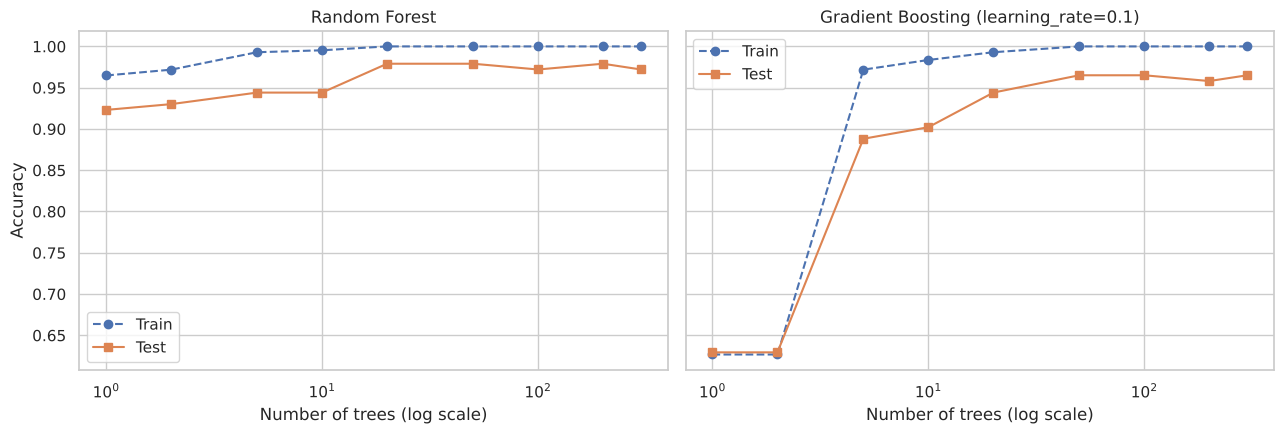

In [8]:
n_list = [1, 2, 5, 10, 20, 50, 100, 200, 300]
rf_te, gb_te, gb_tr, rf_tr = [], [], [], []
for n in n_list:
    r = RandomForestClassifier(n_estimators=n, random_state=0).fit(X_train, y_train)
    g = GradientBoostingClassifier(n_estimators=n, learning_rate=0.1, random_state=0).fit(X_train, y_train)
    rf_te.append(r.score(X_test, y_test)); rf_tr.append(r.score(X_train, y_train))
    gb_te.append(g.score(X_test, y_test)); gb_tr.append(g.score(X_train, y_train))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ax[0].plot(n_list, rf_tr, "o--", label="Train"); ax[0].plot(n_list, rf_te, "s-", label="Test")
ax[0].set_title("Random Forest"); ax[1].plot(n_list, gb_tr, "o--", label="Train"); ax[1].plot(n_list, gb_te, "s-", label="Test")
ax[1].set_title("Gradient Boosting (learning_rate=0.1)")
for a in ax: a.set_xscale("log"); a.set_xlabel("Number of trees (log scale)"); a.legend()
ax[0].set_ylabel("Accuracy"); plt.tight_layout(); plt.show()

**How to read these:**
- **Random Forest:** with 1 tree it behaves like a single tree (test accuracy about 0.92); it rises to about **0.97 to 0.98 by 20 trees** and then stays flat. It does **not** get worse as trees are added, which shows that bagging is robust to adding trees.
- **Gradient Boosting:** with 1 or 2 trees and a learning rate of 0.1, the model has barely moved from its starting prediction and still predicts the majority class for everyone, so accuracy is only about 0.63 (the Dummy level). It then climbs to about **0.96 by 50 trees**, and afterwards fluctuates slightly (0.958 to 0.965) while training accuracy is already 1.0. A *small* learning rate needs many trees; this is the learning-rate vs number-of-trees trade-off.
- Small wiggles in the test curves are noise from a small test set (143 samples: one sample is about 0.7%), not real overfitting.

## Step 7: Out-of-bag (OOB) estimate

Each tree in a Random Forest is trained on a **bootstrap sample** (drawn with replacement), which leaves out about **37%** of the rows. Those **out-of-bag** rows act as a free validation set for that tree. The OOB score is an honest accuracy estimate without a separate test set.

In [9]:
rf_oob = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42).fit(X_train, y_train)
print("OOB accuracy : %.4f" % rf_oob.oob_score_)
print("Test accuracy: %.4f" % rf_oob.score(X_test, y_test))
print("Expected share of unique rows in a bootstrap sample: %.1f%%" % (100 * (1 - (1 - 1 / len(X_train)) ** len(X_train))))

OOB accuracy : 0.9554
Test accuracy: 0.9580
Expected share of unique rows in a bootstrap sample: 63.3%


The OOB accuracy is close to the test accuracy, so it can replace a validation set.

## Result / Conclusion
- The majority-class Dummy model has no predictive power (recall 0), and the single Decision Tree is a reasonable baseline (test accuracy 0.958, CV accuracy 0.926, AUC 0.947). All three ensembles beat it in **AUC (about 0.995)** and **cross-validated accuracy (0.953 to 0.977)**; on the single test split their accuracy is only slightly higher (Random Forest equals the tree), so the evidence for the improvement comes mainly from AUC and cross-validation. AdaBoost was the best and most stable model in this run.
- **Bagging** reduces variance (many de-correlated trees averaged); **boosting** reduces bias (each tree corrects the previous errors). Random Forest is robust to adding trees; boosting needs care (learning rate, number of trees).
- The trade-off: ensembles are less interpretable and cost more to train and store.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is ensemble learning?**
Combining multiple models (weak learners) to get a better, more stable model than any single one.

**Q2. Types of ensemble methods?**
Bagging (Random Forest), Boosting (AdaBoost, Gradient Boosting, XGBoost), Stacking and Voting.

**Q3. What is bagging?**
Bootstrap Aggregating: train many models on random samples drawn with replacement, then average (regression) or vote (classification). It reduces **variance**.

**Q4. What is Random Forest?**
An ensemble of decision trees built with bagging **plus random feature selection at each split**, which de-correlates the trees. The final output is the majority vote.

**Q5. Why does Random Forest beat a single tree?**
A single deep tree overfits (high variance). Averaging many different trees cancels individual errors and reduces variance.

**Q6. What is a bootstrap sample and OOB error?**
A bootstrap sample is drawn with replacement from the training data (about 63% unique rows). The remaining ~37% (out-of-bag) rows give a free error estimate (`oob_score=True`).

**Q7. What is boosting?**
Sequentially training weak learners where each tries to correct the errors of the previous ones, giving more weight to misclassified examples. It mainly reduces **bias**.

**Q8. AdaBoost vs Gradient Boosting?**
AdaBoost re-weights misclassified samples and combines learners with weights. Gradient Boosting fits each new tree to the residual errors (the negative gradient of the loss).

**Q9. Key hyperparameters of Random Forest?**
`n_estimators`, `max_depth`, `max_features`, `min_samples_split`, `min_samples_leaf`.

**Q10. Key hyperparameters of boosting?**
`n_estimators`, `learning_rate` (smaller rate needs more trees), `max_depth`, `subsample`.

**Q11. Which one is more prone to overfitting?**
Boosting, especially with many rounds and a high learning rate. Random Forest is more robust.

**Q12. What is a weak learner?**
A model only slightly better than random guessing, such as a shallow tree (stump).

**Q13. Is scaling required for tree ensembles?**
No, trees split on thresholds and are scale-invariant.

**Q14. How is feature importance calculated?**
By the total decrease in impurity (Gini or entropy) contributed by splits on that feature, averaged over all trees.

**Q15. What is a baseline model and why use it?**
A simple model used as a reference. If a complex model cannot beat it, the added complexity is not justified. The Dummy model is the lowest bar; the single decision tree is the practical baseline.

**Q16. What are the disadvantages of ensembles?**
Less interpretable, higher computation and memory, longer training time.

**Q17. What is a decision tree and what is Gini impurity?**
A tree-shaped model that splits data on feature thresholds. Gini = $1-\sum p_i^2$; it is 0 for a pure node, and the best split reduces it the most.

**Q18. What is stacking?**
Training a meta-model on the predictions of several different base models.

**Q19. Bagging vs boosting?**
Bagging: parallel, independent trees on bootstrap samples, reduces variance. Boosting: sequential trees, each fixing the previous errors, reduces bias.

**Q20. Why does a single decision tree reach 100% training accuracy?**
An unrestricted tree keeps splitting until every leaf is pure, memorising the training data: overfitting.

**Q21. Why is `max_features` important in Random Forest?**
Using only a random subset of features at each split forces trees to be different (de-correlated), which makes averaging more effective.

**Q22. What is XGBoost?**
An optimised, regularised implementation of gradient boosting that is fast and widely used.

**Q23. How does a Random Forest do regression?**
Each tree predicts a number, and the forest averages them.

**Q24. Can feature importance be misleading?**
Yes: it is biased toward features with many unique values, splits importance across correlated features, and gives no direction of effect. Permutation importance is a more reliable alternative.

## B. Questions about the graphs

**G1. What does the feature importance bar plot show?**
The contribution of each feature to reducing impurity across all trees, normalised to sum to 1. Long bars (for example worst perimeter, worst concave points) mean influential features.

**G2. Can importance tell the direction of the effect?**
No, only the strength.

**G3. What does the model comparison bar chart show?**
Test metrics for each model. The Dummy is lowest; the ensembles are slightly higher than the baseline tree in accuracy and clearly higher in AUC, meaning combining many learners improves ranking quality. Be honest that accuracy differences on a 143-sample test set are small.

**G3b. Your Random Forest had the same accuracy as the single tree. Does that mean it is no better?**
Not necessarily. On one 143-sample test split, accuracy is noisy (one patient = 0.7%). The Random Forest has a much higher AUC (0.995 vs 0.947) and a higher cross-validated accuracy (0.953 vs 0.926), which are more reliable measures.

**G4. What does the accuracy-vs-number-of-trees plot show?**
For Random Forest accuracy rises then plateaus, so more trees does not overfit. For boosting, test accuracy plateaus (and can drop with too many rounds) while training accuracy keeps rising.

**G5. How do the confusion matrices of the ensembles compare with the tree?**
Fewer off-diagonal entries (errors), especially fewer false negatives.

**G6. What does the cross-validation boxplot show?**
The distribution of accuracy across folds. Higher and narrower boxes mean better and more stable models. In my run the single tree is lowest (0.926) and AdaBoost is highest and narrowest (0.977); Random Forest and Gradient Boosting have higher means than the tree but not a clearly smaller spread.

**G7. What do the ROC curves show?**
The trade-off between true positive rate and false positive rate for each model; curves nearer the top-left (larger AUC) are better. The tree's curve is blocky because a tree gives few distinct probabilities.

## C. Code questions

**C1. Why `stratify=y`?**
To keep the same class proportion in train and test.

**C2. What does `n_estimators` mean?**
The number of trees in the ensemble.

**C3. What does `predict_proba` return for a forest?**
The average of the class probabilities predicted by all trees.

**C4. Why is `random_state` set?**
Bootstrap sampling and feature selection are random; the seed makes results reproducible.

**C5. What does `DummyClassifier(strategy='most_frequent')` do?**
Always predicts the most common training class. It gives the minimum performance any real model should beat.